# 00 — Chuẩn bị dữ liệu (chạy một lần)
Tải 30 lớp từ Hugging Face, loại ảnh trùng, tạo split 70/15/15, kiểm tra split có khớp với split cũ trong repo không,
rồi lưu data đã làm sạch lên Drive. Các notebook sau chỉ cần giải nén lại, không tải lại.

## 0. Chuẩn bị phiên Colab
Chạy cell này **mỗi lần mở notebook** (kể cả sau khi Colab bị ngắt). Nhớ bật GPU: *Runtime → Change runtime type → T4 GPU*.
Cell tự kiểm tra code trên Colab khớp với bản Claude vừa sync (hash). Nếu Claude sync lại trong lúc notebook đang mở: *Runtime → Restart session* rồi chạy lại từ cell này.

In [1]:
from google.colab import drive
drive.mount("/content/drive")
import shutil, sys
DRIVE = "/content/drive/MyDrive/DL/vnfood_colab"
RUNS = f"{DRIVE}/runs"
print(open(f"{DRIVE}/code/VERSION.txt").read())
shutil.copytree(f"{DRIVE}/code", "/content/vnfood", dirs_exist_ok=True,
                ignore=shutil.ignore_patterns("data", "models"))
%cd /content/vnfood
!pip -q install datasets streamlit pytest
sys.path.insert(0, "/content/vnfood")
from colab import session
expected = session.read_version(f"{DRIVE}/code/VERSION.txt")["content_hash"]
actual = session.code_hash("/content/vnfood")
assert actual == expected, (f"Code chưa đồng bộ xong (hash {actual} != {expected}). Đợi 1-2 phút rồi chạy lại cell này; "
                            "nếu vẫn lệch: Runtime > Restart session rồi chạy lại.")
print("Code khớp Drive, hash:", actual)
print("GPU:", session.check_gpu())

Mounted at /content/drive
version=530c7a4-dirty-20261123134500
commit=530c7a45ce997f0f93ae3a15871878b3231e74e0
dirty=yes
synced_at=2026-11-23T06:45:00Z
content_hash=5ad5134f9b68b0ba

/content/vnfood
Code khớp Drive, hash: 5ad5134f9b68b0ba
GPU: Tesla T4


## 1. Kiểm tra code (pytest)
Phải thấy toàn bộ test **passed**. Nếu có test fail, copy toàn bộ output gửi Claude trước khi chạy tiếp.

In [2]:
!python -m pytest -q colab/tests

......................................                                   [100%]
38 passed in 30.28s


## 2. Tải và làm sạch dữ liệu
Mất khoảng 15–30 phút ở lần đầu. Nếu Drive đã có `data/raw.zip` thì cell chỉ giải nén lại.

In [3]:
import json
from pathlib import Path
repo = Path("/content/vnfood")
if session.restore_data():
    print("Đã khôi phục data từ Drive — bỏ qua bước tải.")
else:
    shutil.copy(repo / "outputs/clean_split_manifest.json", repo / "outputs/clean_split_manifest.repo.json")
    !python src/dataset.py
    !python src/data_cleaning.py --apply
    original = json.loads((repo / "outputs/clean_split_manifest.repo.json").read_text())
    fresh = json.loads((repo / "outputs/clean_split_manifest.json").read_text())
    result = session.compare_manifests(original, fresh)
    print(json.dumps(result, indent=2))
    print("SPLIT KHỚP REPO: OK" if result["same"] else "SPLIT KHÁC REPO — gửi output này cho Claude")
    session.save_data()
    print("Đã lưu data/raw.zip và manifest lên Drive.")

README.md: 100% 1.35k/1.35k [00:00<00:00, 765kB/s]

data/train-00000-of-00006.parquet: downloading bytes:  34% 167M/491M [00:02<00:02, 154MB/s, 9.48MB/s  ]  
data/train-00000-of-00006.parquet: downloading bytes:  73% 357M/491M [00:02<00:00, 317MB/s, 28.0MB/s  ]
data/train-00000-of-00006.parquet: downloading bytes:  89% 438M/491M [00:02<00:00, 345MB/s, 36.0MB/s  ]
data/train-00000-of-00006.parquet: downloading bytes: 100% 490M/491M [00:02<00:00, 314MB/s, 42.8MB/s  ]
data/train-00000-of-00006.parquet: downloading bytes: 100% 491M/491M [00:03<00:00, 127MB/s, 43.5MB/s  ]
data/train-00000-of-00006.parquet: reconstructing file: 100% 491M/491M [00:03<00:00, 127MB/s, 43.5MB/s  ]

data/train-00001-of-00006.parquet: downloading bytes:  97% 528M/544M [00:02<00:00, 531MB/s, 41.8MB/s  ]
data/train-00001-of-00006.parquet: reconstructing file:  49% 268M/544M [00:02<00:02, 93.6MB/s]
data/train-00001-of-00006.parquet: downloading bytes: 100% 544M/544M [00:05<00:00, 98.5MB/s, 49.0MB/s  ]
data/train-0000

## 3. EDA: phân bố lớp và ảnh mẫu

Created EDA for 30 classes and 24886 images.


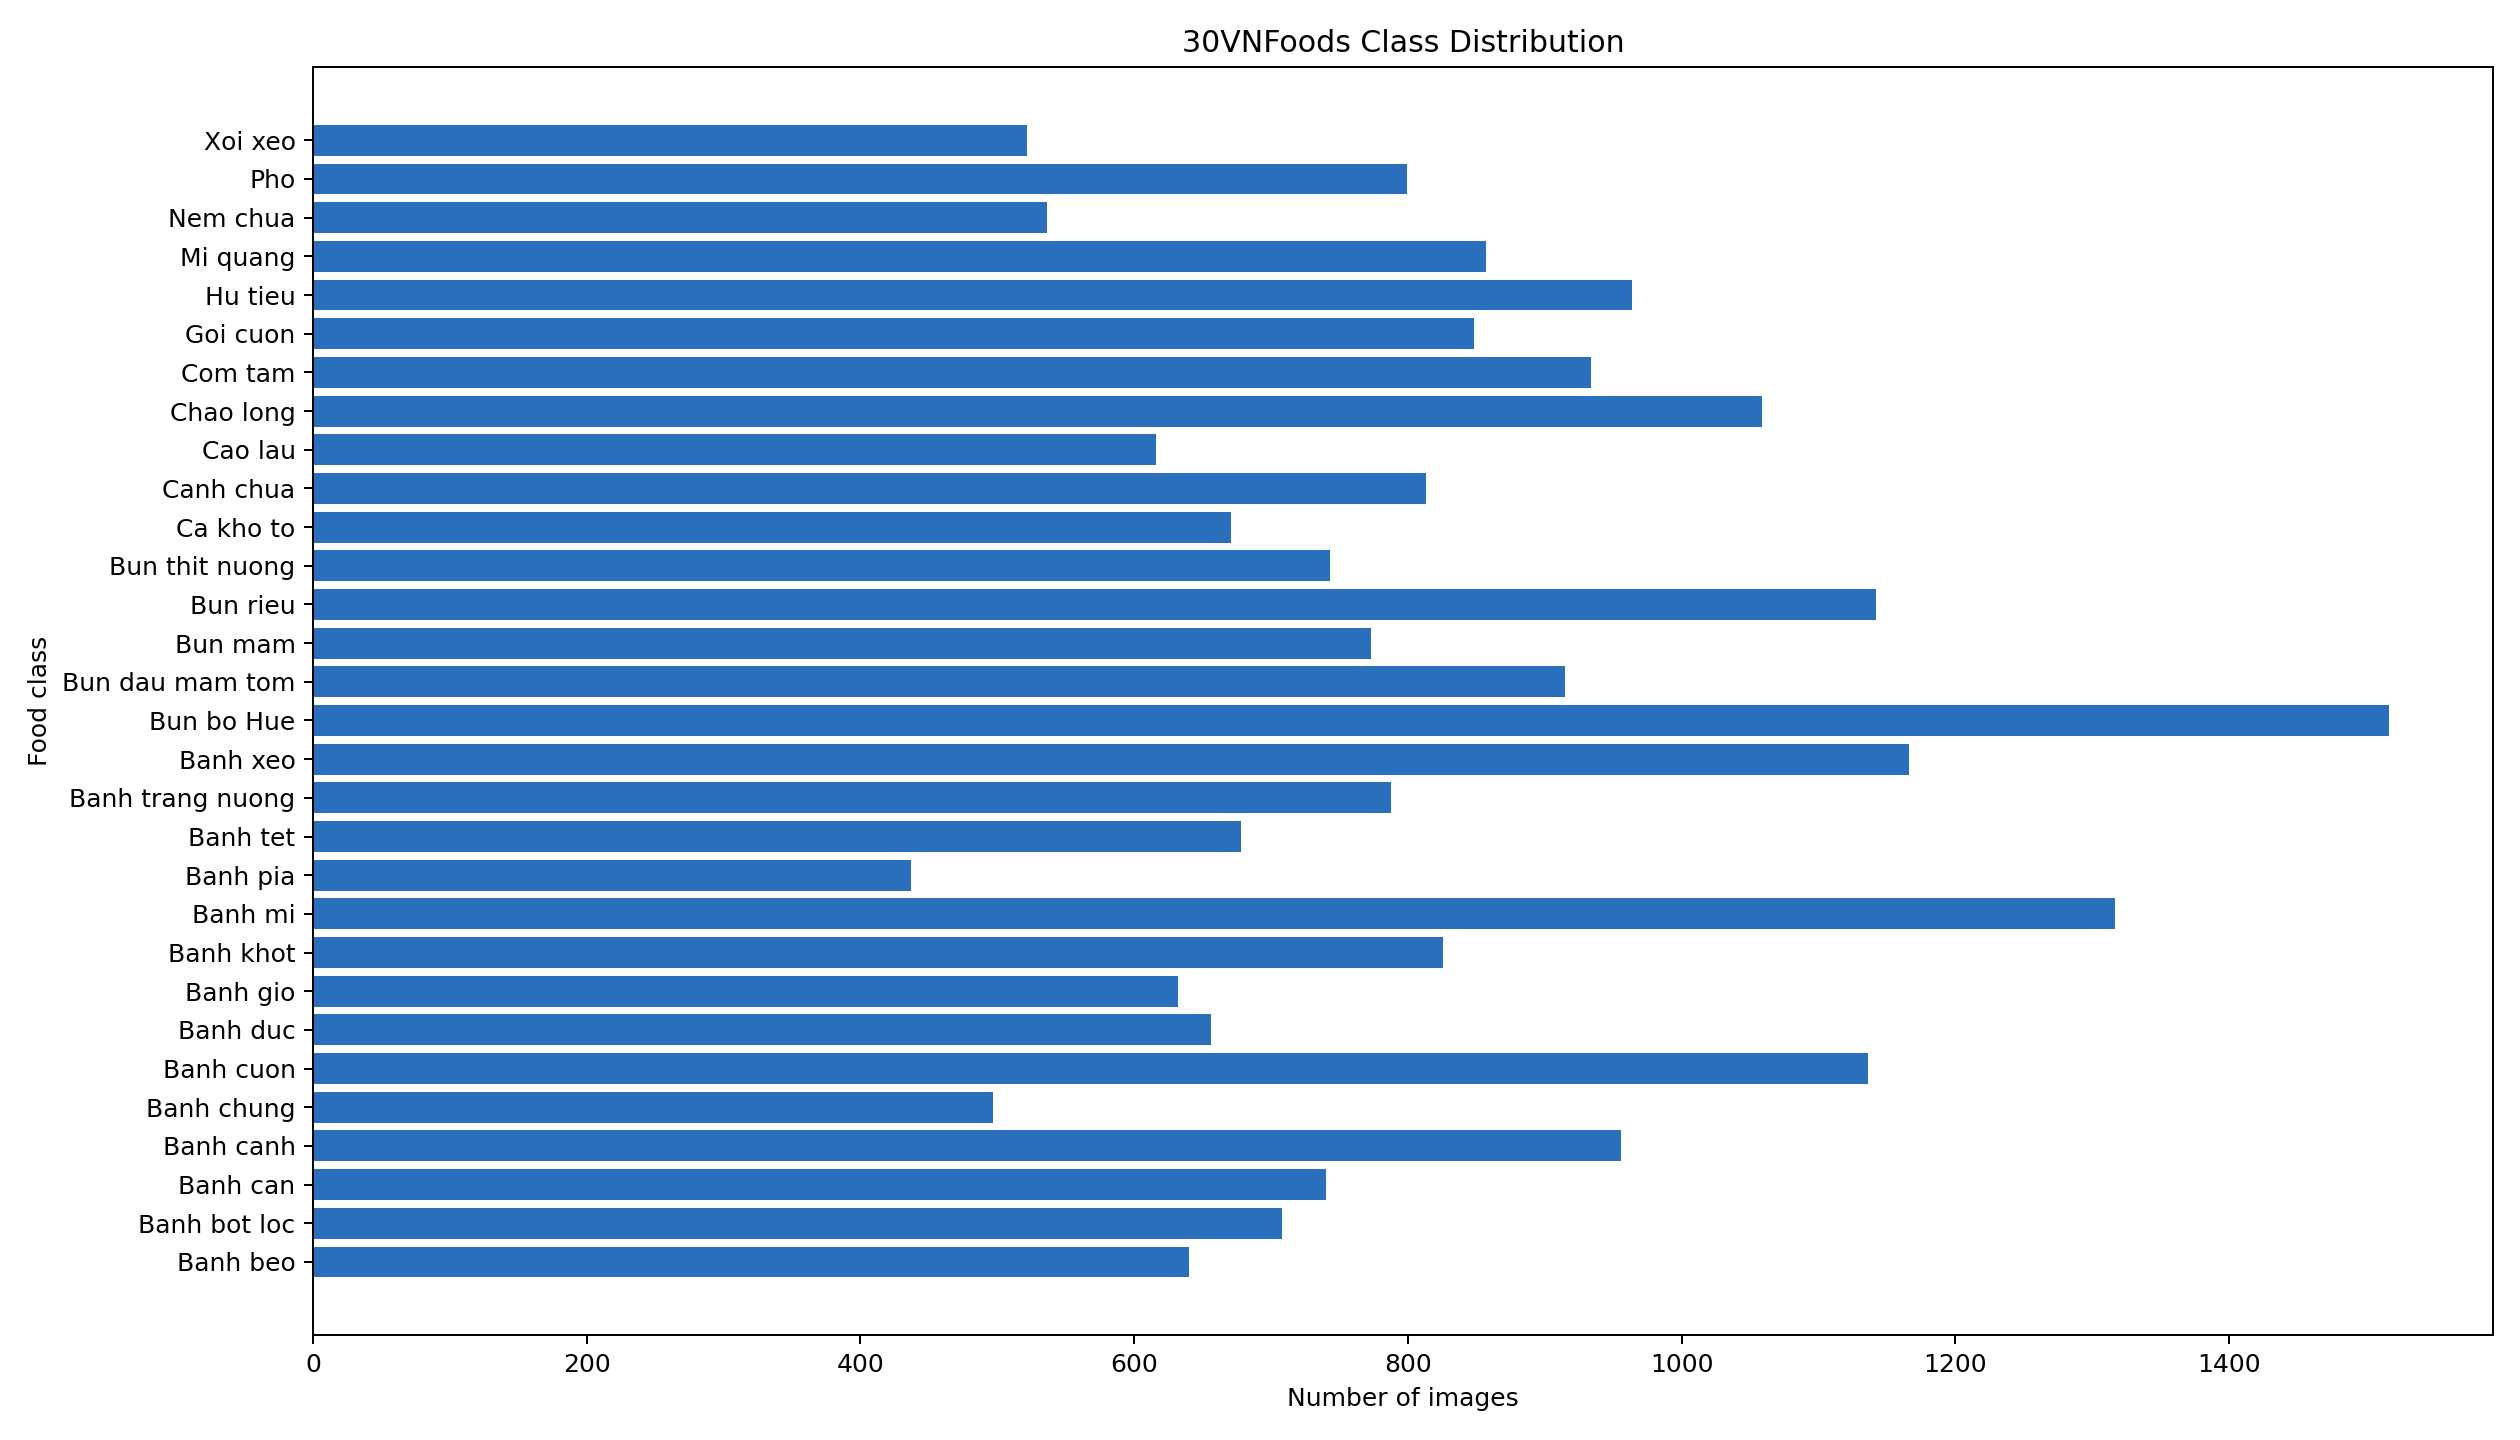

In [4]:
!python src/eda.py
eda_dir = Path(RUNS) / "_eda"
eda_dir.mkdir(parents=True, exist_ok=True)
for name in ("class_distribution.png", "sample_images.png"):
    shutil.copy(repo / "outputs/figures" / name, eda_dir / name)
shutil.copy(repo / "outputs/eda_summary.json", eda_dir / "eda_summary.json")
from IPython.display import Image as Show, display
display(Show(str(eda_dir / "class_distribution.png")))